# Highway Networks on CIFAR-10

Paper: R. K. Srivastava, K. Greff, J. Schmidhuber, *Highway Networks*, [arXiv:1505.00387](https://arxiv.org/abs/1505.00387).

$$y = H(x)\cdot T(x) + x\cdot\big(1 - T(x)\big), \qquad T(x) = \sigma(W_T x + b_T)$$

In [1]:
import time, json
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.transforms as T
import matplotlib.pyplot as plt

SEED = 31287
torch.manual_seed(SEED)
np.random.seed(SEED)

DEVICE = ("mps" if torch.backends.mps.is_available()
          else "cuda" if torch.cuda.is_available() else "cpu")
EPOCHS = 40
BATCH_SIZE = 128
DATA_DIR = "../_data"
print(f"device={DEVICE}, torch={torch.__version__}")

device=mps, torch=2.14.1


## 1. Data: CIFAR-10

In [2]:
# Per-channel mean/std of the training images, -> (0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616)
pixels = torch.tensor(torchvision.datasets.CIFAR10(DATA_DIR, train=True, download=True).data, dtype=torch.float32) / 255
MEAN, STD = pixels.mean((0, 1, 2)).tolist(), pixels.std((0, 1, 2)).tolist()
del pixels

train_tf = T.Compose([T.RandomCrop(32, padding=4), T.RandomHorizontalFlip(),
                      T.ToTensor(), T.Normalize(MEAN, STD)])
eval_tf = T.Compose([T.ToTensor(), T.Normalize(MEAN, STD)])

# Two views of the same training files: augmented for training, clean for validation.
train_full = torchvision.datasets.CIFAR10(DATA_DIR, train=True, download=True, transform=train_tf)
val_full = torchvision.datasets.CIFAR10(DATA_DIR, train=True, download=True, transform=eval_tf)
test_set = torchvision.datasets.CIFAR10(DATA_DIR, train=False, download=True, transform=eval_tf)
CLASSES = test_set.classes

perm = torch.randperm(len(train_full), generator=torch.Generator().manual_seed(SEED))
train_idx, val_idx = perm[:45_000], perm[45_000:]

loader = lambda ds, shuffle: torch.utils.data.DataLoader(
    ds, batch_size=BATCH_SIZE, shuffle=shuffle, num_workers=4, persistent_workers=True)
train_loader = loader(torch.utils.data.Subset(train_full, train_idx), True)
val_loader = loader(torch.utils.data.Subset(val_full, val_idx), False)
test_loader = loader(test_set, False)
print(len(train_idx), len(val_idx), len(test_set))

45000 5000 10000


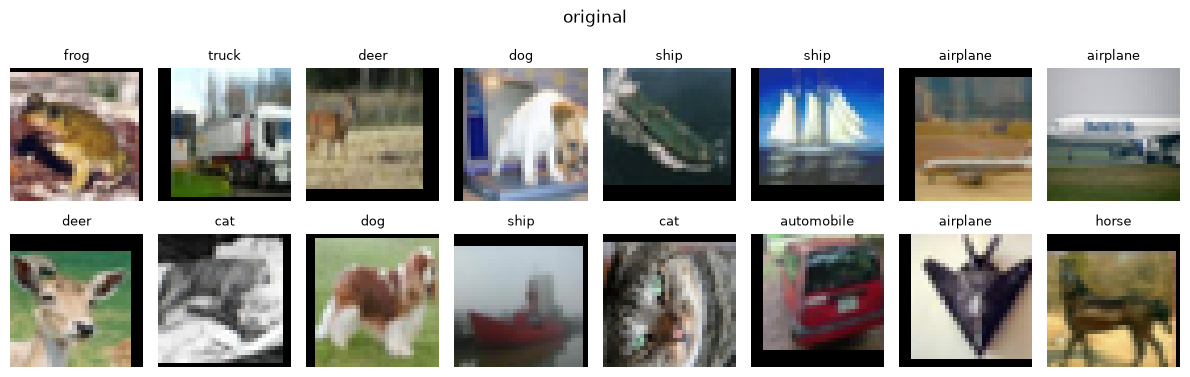

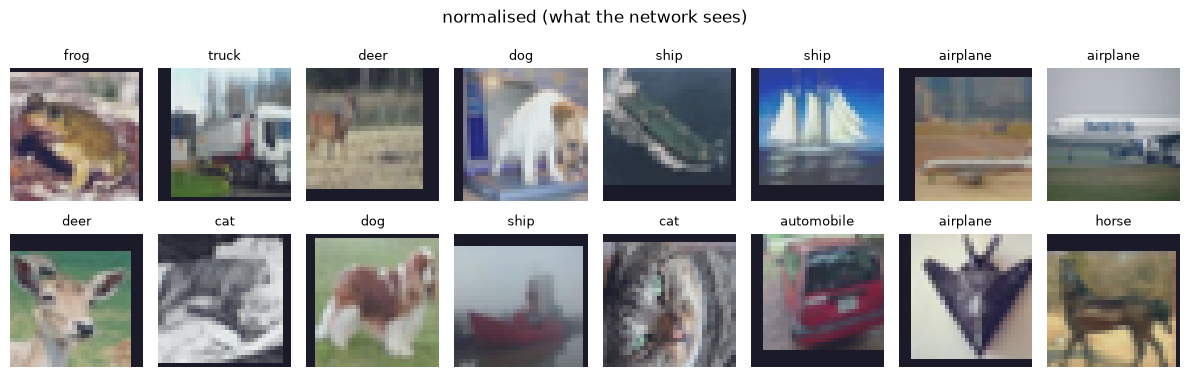

In [ ]:
# A few training images: de-normalised for display, and as the network gets them (normalised).
imgs, labels = next(iter(train_loader))
imgs = imgs[:16]
mean, std = torch.tensor(MEAN).view(3, 1, 1), torch.tensor(STD).view(3, 1, 1)


def show(batch, title):
    fig, axes = plt.subplots(2, 8, figsize=(12, 4))
    for ax, img, lab in zip(axes.flat, batch, labels):
        ax.imshow(img.permute(1, 2, 0).clamp(0, 1))
        ax.set_title(CLASSES[lab], fontsize=9)
        ax.axis("off")
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


show(imgs * std + mean, "original")
show((imgs + 2.5) / 5, "normalised (what the network sees)")

## 2. Model

In [ ]:
def conv_bn_relu(c_in, c_out, k=3):
    return nn.Sequential(nn.Conv2d(c_in, c_out, k, padding=k // 2, bias=False),
                         nn.BatchNorm2d(c_out), nn.ReLU(inplace=True))


class HighwayConv(nn.Module):
    # y = H(x) * T(x) + x * (1 - T(x))
    def __init__(self, c, gate_bias=-2.0):
        super().__init__()
        self.h = conv_bn_relu(c, c)
        self.t = nn.Conv2d(c, c, 3, padding=1)
        # Negative bias -> T ~ sigmoid(-2) ~ 0.12 at init: the layer starts close to identity.
        nn.init.constant_(self.t.bias, gate_bias)

    def forward(self, x):
        t = torch.sigmoid(self.t(x))
        return self.h(x) * t + x * (1 - t)


class PlainConv(nn.Module):
    def __init__(self, c, **_):
        super().__init__()
        self.h = conv_bn_relu(c, c)

    def forward(self, x):
        return self.h(x)


def make_net(block, n_blocks, gate_bias=-2.0, widths=(32, 64, 128)):
    # n_blocks = number of highway/plain blocks, split evenly over the 3 stages
    per_stage = n_blocks // len(widths)
    layers = [conv_bn_relu(3, widths[0])]
    for i, c in enumerate(widths):
        if i > 0:
            layers += [nn.MaxPool2d(2), conv_bn_relu(widths[i - 1], c, k=1)]
        layers += [block(c, gate_bias=gate_bias) for _ in range(per_stage)]
    layers += [nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(widths[-1], 10)]
    return nn.Sequential(*layers)


def n_params(model):
    return sum(p.numel() for p in model.parameters())


# Sanity checks: shape is preserved, and a strongly closed gate makes the block an identity.
x = torch.randn(4, 32, 16, 16)
assert HighwayConv(32)(x).shape == x.shape
assert torch.allclose(HighwayConv(32, gate_bias=-30.0)(x), x, atol=1e-4)

for name, blk in [("highway", HighwayConv), ("plain", PlainConv)]:
    m = make_net(blk, 18)
    print(f"{name:8s} 18 blocks: {n_params(m):>9,} params")

highway  18 blocks: 2,339,306 params
plain    18 blocks: 1,176,746 params


## 3. Training

In [ ]:
def run_epoch(model, loader, opt=None):
    model.train(opt is not None)
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(opt is not None):
        for x, y in loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            out = model(x)
            loss = F.cross_entropy(out, y)
            if opt is not None:
                opt.zero_grad()
                loss.backward()
                opt.step()
            total_loss += loss.item() * len(y)
            correct += (out.argmax(1) == y).sum().item()
            n += len(y)
    return total_loss / n, correct / n


def train(model, epochs, lr=0.05):
    model.to(DEVICE)
    # no weight decay on the gate biases, otherwise it pulls them towards 0 and opens the gates by itself
    gate_biases = [m.t.bias for m in model.modules() if isinstance(m, HighwayConv)]
    other = [p for p in model.parameters() if all(p is not b for b in gate_biases)]
    opt = torch.optim.SGD([{"params": other}, {"params": gate_biases, "weight_decay": 0.0}],
                          lr=lr, momentum=0.9, weight_decay=5e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, epochs)
    hist = {k: [] for k in ["train_loss", "train_acc", "val_loss", "val_acc"]}
    for ep in range(epochs):
        t0 = time.time()
        tl, ta = run_epoch(model, train_loader, opt)
        vl, va = run_epoch(model, val_loader)
        sched.step()
        for k, v in zip(hist, (tl, ta, vl, va)):
            hist[k].append(v)
        print(f"ep {ep + 1:2d}/{epochs}  train {tl:.3f}/{ta:.3f}  val {vl:.3f}/{va:.3f}  {time.time() - t0:.0f}s")
    return hist

## 4. Experiments: highway vs plain, 18 and 48 blocks

In [6]:
# Plain nets are ~sqrt(2)x wider, so they have the same number of parameters as the highway nets
# (a highway block has two convolutions: H and the gate T), as in the paper.
EXPERIMENTS = [  # (name, block, n_blocks, gate_bias, widths)
    ("highway-18", HighwayConv, 18, -2.0, (32, 64, 128)),
    ("plain-18", PlainConv, 18, None, (45, 90, 180)),
    ("highway-48", HighwayConv, 48, -4.0, (32, 64, 128)),
    ("plain-48", PlainConv, 48, None, (45, 90, 180)),
]

histories, results = {}, {}
for name, blk, depth, bias, widths in EXPERIMENTS:
    print(f"\n=== {name} ===")
    torch.manual_seed(SEED)
    model = make_net(blk, depth, gate_bias=bias, widths=widths)
    t0 = time.time()
    histories[name] = train(model, EPOCHS)
    test_loss, test_acc = run_epoch(model, test_loader)
    results[name] = {"params": n_params(model), "epochs": EPOCHS, "test_loss": test_loss,
                     "test_acc": test_acc, "minutes": (time.time() - t0) / 60}
    print(f"{name}: test acc {test_acc:.4f}")
    torch.save(model.state_dict(), f"{name}.pt")  # weights for highway_extras.ipynb

with open("results.json", "w") as f:
    json.dump({"results": results, "histories": histories}, f, indent=1)


=== highway-18 ===


ep  1/40  train 1.461/0.459  val 1.468/0.542  72s


ep  2/40  train 0.952/0.659  val 1.246/0.624  66s


ep  3/40  train 0.757/0.733  val 1.102/0.665  68s


ep  4/40  train 0.645/0.776  val 0.990/0.681  70s


...

ep 37/40  train 0.585/0.798  val 0.636/0.783  128s


ep 38/40  train 0.571/0.802  val 0.628/0.785  128s


ep 39/40  train 0.563/0.803  val 0.620/0.789  128s


ep 40/40  train 0.563/0.805  val 0.620/0.789  128s


plain-48: test acc 0.7867


## 5. Results

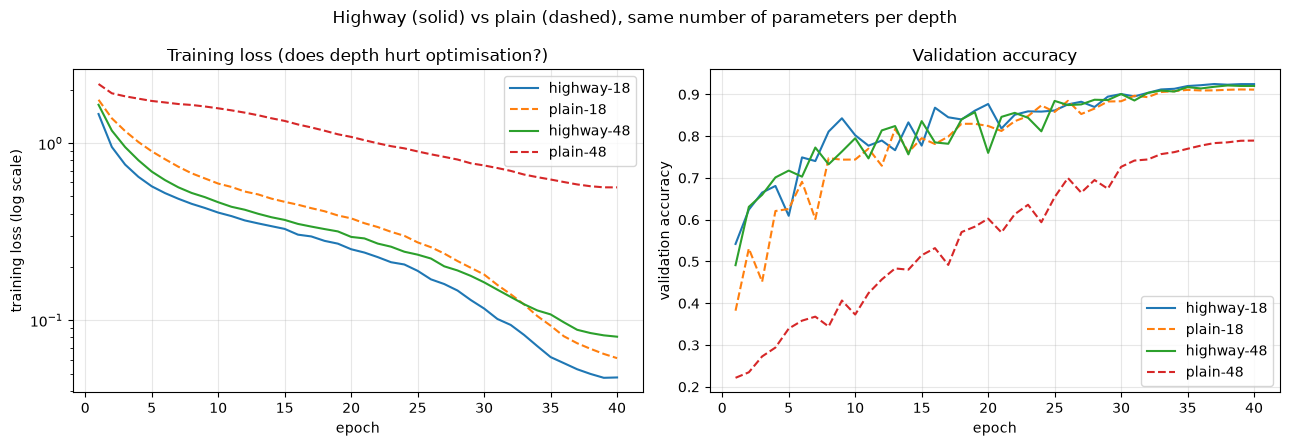

model              params  test acc time [min]
highway-18      2,339,306    0.9182       43.5
plain-18        2,324,035    0.9078       37.0
highway-48      6,216,746    0.9133      105.9
plain-48        6,157,585    0.7867       86.7


In [7]:
fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(13, 4.5))
for name, hist in histories.items():
    style = "-" if name.startswith("highway") else "--"
    ep = range(1, len(hist["train_loss"]) + 1)
    ax_loss.plot(ep, hist["train_loss"], style, label=name)
    ax_acc.plot(ep, hist["val_acc"], style, label=name)
ax_loss.set(yscale="log", xlabel="epoch", ylabel="training loss (log scale)",
            title="Training loss (does depth hurt optimisation?)")
ax_acc.set(xlabel="epoch", ylabel="validation accuracy", title="Validation accuracy")
for ax in (ax_loss, ax_acc):
    ax.legend()
    ax.grid(alpha=0.3)
fig.suptitle("Highway (solid) vs plain (dashed), same number of parameters per depth")
plt.tight_layout()
plt.show()

print(f"{'model':14s} {'params':>10s} {'test acc':>9s} {'time [min]':>10s}")
for name, r in results.items():
    print(f"{name:14s} {r['params']:>10,} {r['test_acc']:>9.4f} {r['minutes']:>10.1f}")